# 経路条件で練習によるMTの短縮量は異なるか

練習1–100試行と301–400試行を比較した。参加者が担当する経路条件は1つで、同じ人について前半と後半を観測している。条件（C1 ベースライン、C2 長距離、C3 幅狭）を参加者間要因、区間を参加者内要因とする3×2の混合計画分散分析を用いる。

- **主分析**では参加者ごとに各区間のcore MTを算術平均し、短縮量（前半平均 − 後半平均、ms）の条件差を交互作用で評価する。
- **補足分析**ではその2つの算術平均を自然対数変換する。前後差は log(前半平均 / 後半平均) であり、交互作用は相対的な変化の条件差を表す。条件別の相対短縮率は「1 − 個人の後半/前半比の幾何平均」で示す。
- 各分析で区間・条件・交互作用のF、自由度、p値、偏η²を示す。参加者内要因は2水準なので球面性は自動的に成立する。各尺度の交互作用が5%水準で有意な場合だけ、その尺度で条件内の前後比較3件と条件間の短縮量比較3件を行い、それぞれの検定群内でHolm補正する。主分析と補足分析は別に解釈する。既にデータの一部を検討した後の再解析である。

In [1]:
import csv
import io
import math
import os
import sys
from collections import Counter, defaultdict
from html import escape
from itertools import combinations
from pathlib import Path

root = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / 'analysis.py').is_file() and (p / 'inputCSV').is_dir())
out = root / 'output/learning_report/core_mt_mixed_anova_20261125_203017'
for key in ('OPENBLAS_NUM_THREADS','OMP_NUM_THREADS','VECLIB_MAXIMUM_THREADS','MKL_NUM_THREADS','NUMEXPR_NUM_THREADS'):
    os.environ[key] = '1'
os.environ.setdefault('MPLCONFIGDIR', str(root / '.cache/matplotlib'))
sys.path.insert(0, str(root))
import numpy as np
from scipy import optimize, stats
from IPython.display import HTML, Image, Markdown, display
from analysis import load_rows

conditions = ('C1','C2','C3')
scales = ('生MT','log平均MT')

def save_csv(name, rows):
    with (out / name).open('w', encoding='utf-8-sig', newline='') as stream:
        writer = csv.DictWriter(stream, fieldnames=list(rows[0]))
        writer.writeheader()
        writer.writerows(rows)

def table(headers, rows):
    h = ''.join('<th>' + escape(str(item)) + '</th>' for item in headers)
    body = ''.join('<tr>' + ''.join('<td>' + escape(str(v)) + '</td>' for v in row)
                   + '</tr>' for row in rows)
    display(HTML(f'<table><thead><tr>{h}</tr></thead><tbody>{body}</tbody></table>'))

def p_text(p):
    return f'{p:.2e}' if p < .001 else f'{p:.4f}'

## 参加者と試行の集計

practiceの元の試行番号を使う。基本採用条件は countedAsTrial=true かつ coreExitMs が有限。successによる選別、MT外れ値除外、休憩境界周辺の除外は行わず、正かつ有限なcoreMtMsを算術平均する。各人を等しく重み付けし、試行を独立な参加者として数えない。

In [2]:
attempts = defaultdict(Counter)
values = defaultdict(list)
assignment = defaultdict(set)
for row in load_rows(root / 'inputCSV'):
    if row['phase'] != 'practice':
        continue
    c, pid, n = row['condition'], row['participant'], row['n']
    assignment[pid].add(c)
    if 1 <= n <= 100:
        period = 'first'
    elif 301 <= n <= 400:
        period = 'last'
    else:
        continue
    key = pid, c, period
    counts = attempts[key]
    counts['records'] += 1
    if not row['countedAsTrial'] or row['coreExitMs'] is None:
        counts['base_excluded'] += 1
        continue
    mt = row['coreMtMs']['MT']
    if mt is None or not math.isfinite(mt) or mt <= 0:
        counts['invalid_MT'] += 1
        continue
    values[key].append(mt)

assert len(assignment) == 30 and all(len(g) == 1 for g in assignment.values())
ids = {c:sorted(pid for pid, g in assignment.items() if c in g) for c in conditions}
assert all(len(ids[c]) == 10 for c in conditions)
observations, data = [], {}
for c in conditions:
    pair = []
    for pid in ids[c]:
        means = []
        for period in ('first','last'):
            key = pid,c,period
            count, valid = attempts[key], values[key]
            assert valid and count['records'] == len(valid) + count['base_excluded'] + count['invalid_MT'], key
            mean = float(np.mean(valid))
            means.append(mean)
            observations.append(dict(subject=pid, cond=c, block=period, MT_ms=mean, log_mean_MT=math.log(mean),
                                     n_valid=len(valid), n_records=count['records'],
                                     n_base_excluded=count['base_excluded'], n_invalid_MT=count['invalid_MT']))
        pair.append(means)
    data[c] = np.asarray(pair)
save_csv('participant_periods.csv', observations)
print(f"{len(assignment)}名、各条件10名。前後とも有効な参加者平均があり、全{len(observations)}セルを採用。")
print(f"両区間の有効試行は計{sum(r['n_valid'] for r in observations)}件。計算は1コア。")

30名、各条件10名。前後とも有効な参加者平均があり、全60セルを採用。
両区間の有効試行は計5988件。計算は1コア。


## 条件別の前後平均と短縮量

短縮量は正であれば後半が速い。msの短縮量と対数比の平均について、それぞれ参加者を単位とする個別95% t信頼区間を求めた。短縮率の信頼区間は対数比の区間を百分率に戻したもの。

In [3]:
def mean_ci(x):
    mean = float(np.mean(x))
    margin = float(stats.t.ppf(.975, len(x)-1) * stats.sem(x))
    return mean, mean-margin, mean+margin

def reduction_pct(log_change):
    return -100 * np.expm1(-np.asarray(log_change))

descriptives = []
for c, m in data.items():
    first, last = m.T
    change = first-last
    diff, lower, upper = mean_ci(change)
    pct, pct_low, pct_high = reduction_pct(mean_ci(np.log(first)-np.log(last)))
    descriptives.append(dict(cond=c, n=len(m), first_ms=first.mean(), last_ms=last.mean(), reduction_ms=diff,
                             reduction_sd_ms=change.std(ddof=1), ci_low_ms=lower, ci_high_ms=upper,
                             geometric_reduction_pct=pct, ci_low_pct=pct_low, ci_high_pct=pct_high))
save_csv('condition_summary.csv', descriptives)
table(['条件','人数','前半 (ms)','後半 (ms)','短縮量 [95% CI] (ms)','相対短縮率 [95% CI] (%)'],
      [[r['cond'],r['n'],f"{r['first_ms']:.1f}",f"{r['last_ms']:.1f}",
        f"{r['reduction_ms']:.1f} [{r['ci_low_ms']:.1f}, {r['ci_high_ms']:.1f}]",
        f"{r['geometric_reduction_pct']:.1f} [{r['ci_low_pct']:.1f}, {r['ci_high_pct']:.1f}]"]
       for r in descriptives])

条件,人数,前半 (ms),後半 (ms),短縮量 [95% CI] (ms),相対短縮率 [95% CI] (%)
C1,10,615.2,424.3,"191.0 [83.2, 298.7]","34.0 [18.5, 46.5]"
C2,10,1408.6,1074.4,"334.3 [157.5, 511.1]","23.3 [11.5, 33.5]"
C3,10,1495.3,1245.0,"250.2 [40.8, 459.7]","16.7 [1.3, 29.8]"


## 条件、区間、条件×区間

2区間の均衡計画なので、参加者の前後平均の中点と前後差を使って混合計画ANOVAを計算できる。条件主効果の誤差項は参加者中点の条件内変動、区間主効果・交互作用の誤差項は参加者の前後差の条件内変動である。交互作用のFは、参加者の前後差を従属変数、条件を参加者間要因とした1要因ANOVAのFと一致する。

偏η² = F × 分子自由度 / (F × 分子自由度 + 分母自由度)。交互作用は、短縮量に対する固定効果1要因モデルの非心F分布を反転し、非心度 λ の両側95%区間を λ/(λ+参加者数) へ変換して、母効果量の区間も示した。

In [4]:
def effect_ci(f, d1, d2, n):
    def bound(prob):
        def residual(nc):
            return (stats.ncf.cdf(f, d1, d2, nc) if nc > 0 else stats.f.cdf(f, d1, d2)) - prob
        if stats.f.cdf(f, d1, d2) <= prob:
            return 0.
        high = 1.
        while residual(high) > 0:
            high *= 2.
        nc = optimize.brentq(residual, 0, high)
        return nc / (n + nc)
    return bound(.975), bound(.025)

def mixed_tests(groups, scale):
    means = [m.mean(axis=1) for m in groups]
    deltas = [m[:,0] - m[:,1] for m in groups]
    n = sum(map(len,groups))
    k = len(groups)
    df_error = n-k
    grand = np.concatenate(deltas).mean()
    err = sum(np.sum((g-g.mean())**2) for g in deltas)
    between = sum(len(g)*(g.mean()-grand)**2 for g in deltas)
    f_interaction = (between/(k-1))/(err/df_error)
    np.testing.assert_allclose(f_interaction, stats.f_oneway(*deltas).statistic, rtol=1e-12)
    effects = [('条件', stats.f_oneway(*means).statistic,k-1),
               ('区間', n*grand**2/(err/df_error),1),
               ('条件×区間',f_interaction,k-1)]
    result = []
    for name,f,d1 in effects:
        low, high = effect_ci(f,d1,df_error,n) if name=='条件×区間' else (None,None)
        result.append(dict(scale=scale,effect=name,F=f,df1=d1,df2=df_error,p=stats.f.sf(f,d1,df_error),
                           partial_eta2=f*d1/(f*d1+df_error),interaction_eta2_ci_low=low,
                           interaction_eta2_ci_high=high))
    return result

groups = {scales[0]:data, scales[1]:{c:np.log(m) for c,m in data.items()}}
anova = [r for scale, values_by_cond in groups.items() for r in mixed_tests(list(values_by_cond.values()),scale)]
save_csv('anova.csv',anova)
table(['尺度','効果','F','df1','df2','p','偏η²','交互作用の偏η² 95% CI'],
      [[r['scale'],r['effect'],f"{r['F']:.3f}",r['df1'],r['df2'],p_text(r['p']),
        f"{r['partial_eta2']:.3f}",'—' if r['interaction_eta2_ci_low'] is None else
        f"[{r['interaction_eta2_ci_low']:.3f}, {r['interaction_eta2_ci_high']:.3f}]"] for r in anova])

尺度,効果,F,df1,df2,p,偏η²,交互作用の偏η² 95% CI
生MT,条件,17.104,2,27,1.59e-05,0.559,—
生MT,区間,35.477,1,27,2.37e-06,0.568,—
生MT,条件×区間,0.917,2,27,0.4117,0.064,"[0.000, 0.241]"
log平均MT,条件,22.427,2,27,1.83e-06,0.624,—
log平均MT,区間,40.654,1,27,7.90e-07,0.601,—
log平均MT,条件×区間,2.268,2,27,0.1229,0.144,"[0.000, 0.346]"


## 下位検定と解釈

各尺度で交互作用が有意だった場合に、条件内では参加者の短縮量に対する両側対応ありt検定（効果量 d_z）、条件間では独立2群の短縮量に対する両側Welchのt検定を適用する。平均差には個別95%信頼区間を付ける。

In [5]:
def adjust_family(family):
    order = np.argsort([r['p'] for r in family])
    previous = 0.
    for rank, idx in enumerate(order):
        previous = min(1., max(previous, (len(family)-rank)*family[idx]['p']))
        family[idx]['p_Holm'] = previous
    return family

followups = []
for scale, by_cond in groups.items():
    interaction = next(r for r in anova if r['scale']==scale and r['effect']=='条件×区間')
    if interaction['p'] >= .05:
        print(f'{scale}の交互作用は5%水準で非有意。事前に定めた手順により下位検定は実施しない。')
        continue
    deltas = {c:m[:,0]-m[:,1] for c,m in by_cond.items()}
    for family, labels in [('条件内',[(c,'') for c in conditions]),('条件間',list(combinations(conditions,2)))]:
        rows = []
        for a,b in labels:
            x = deltas[a]
            if b:
                y = deltas[b]
                test = stats.ttest_ind(x,y,equal_var=False)
                estimate, dz = x.mean()-y.mean(), None
            else:
                test = stats.ttest_1samp(x,0)
                estimate, dz = x.mean(), x.mean()/x.std(ddof=1)
            ci = test.confidence_interval(.95)
            rows.append(dict(scale=scale, family=family, left=a, right=b, difference=estimate,
                             ci_low=ci.low, ci_high=ci.high, t=test.statistic, df=test.df, p=test.pvalue, dz=dz))
        followups.extend(adjust_family(rows))
if followups:
    save_csv('followups.csv',followups)
    table(['尺度','比較','左','右','差','95% CI','p','Holm p','d_z'],
          [[r['scale'],r['family'],r['left'],r['right'] or '0',f"{r['difference']:.4f}",
            f"[{r['ci_low']:.4f}, {r['ci_high']:.4f}]",p_text(r['p']),p_text(r['p_Holm']),
            '—' if r['dz'] is None else f"{r['dz']:.3f}"] for r in followups])
for scale in scales:
    result = {r['effect']:r for r in anova if r['scale']==scale}
    i = result['条件×区間']
    question = '絶対的な短縮量' if scale==scales[0] else '相対的な短縮率'
    conclusion = 'に条件差が認められた' if i['p'] < .05 else 'の条件差は確認できなかった'
    display(Markdown(f"**{scale}**　{question}{conclusion}（条件×区間 F({i['df1']}, {i['df2']}) = "
                     f"{i['F']:.3f}, p = {p_text(i['p'])}, 偏η² = {i['partial_eta2']:.3f}）。"))

生MTの交互作用は5%水準で非有意。事前に定めた手順により下位検定は実施しない。
log平均MTの交互作用は5%水準で非有意。事前に定めた手順により下位検定は実施しない。


**生MT**　絶対的な短縮量の条件差は確認できなかった（条件×区間 F(2, 27) = 0.917, p = 0.4117, 偏η² = 0.064）。

**log平均MT**　相対的な短縮率の条件差は確認できなかった（条件×区間 F(2, 27) = 2.268, p = 0.1229, 偏η² = 0.144）。

## 参加者ごとの変化

左図の細線は同じ参加者の前半・後半で、太線は条件平均。右図の各点は1名の短縮量、横線と縦棒は条件の平均短縮量と個別95%信頼区間。両図の単位はms。

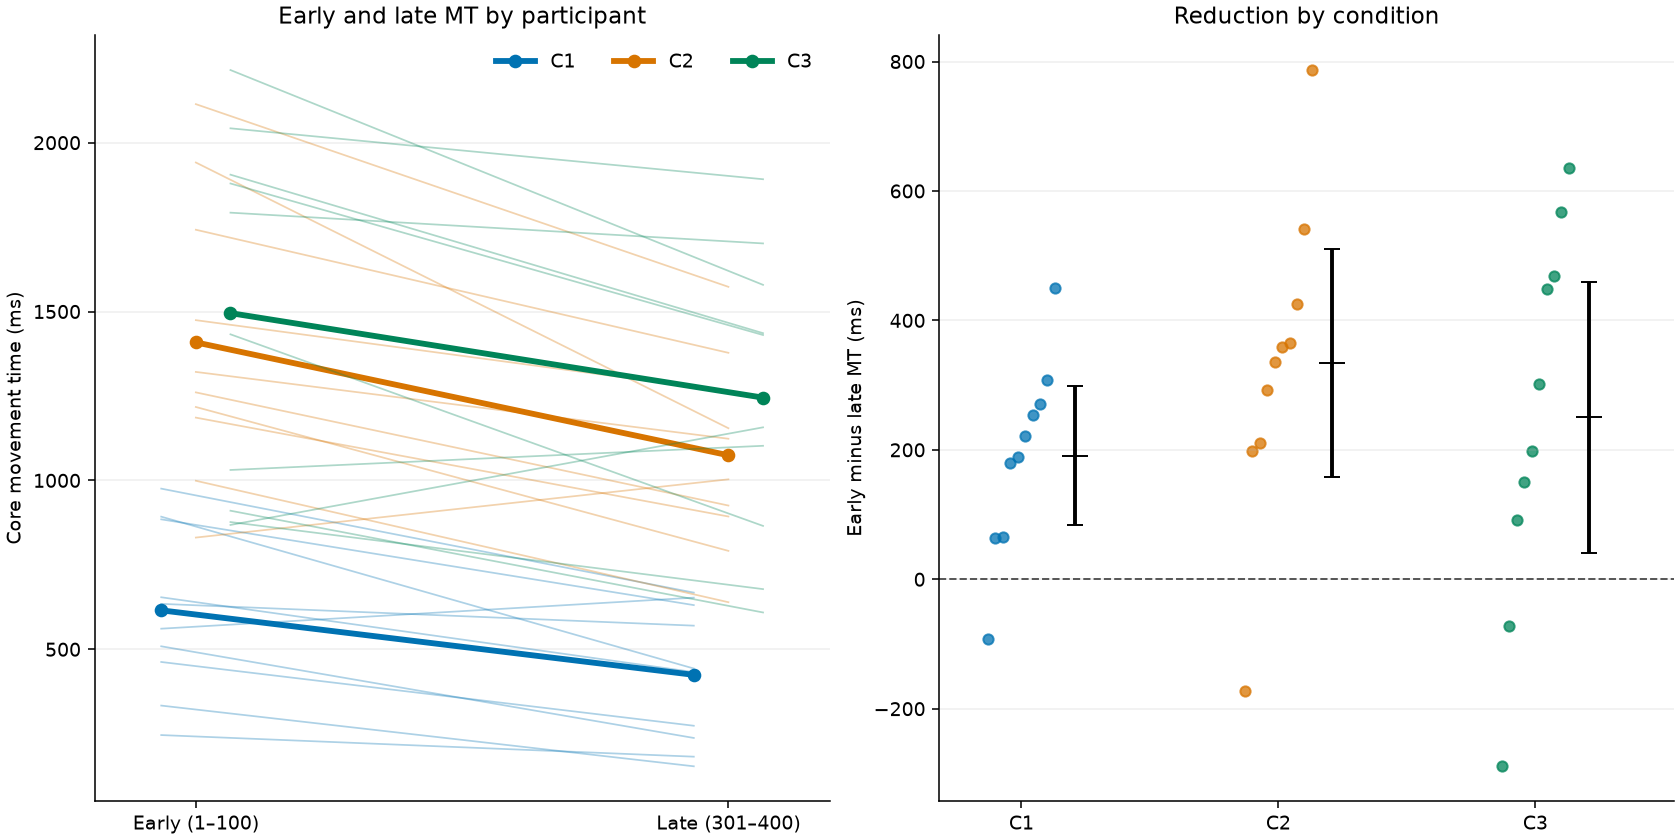

In [6]:
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt

colors = {'C1':'#0072B2','C2':'#D77400','C3':'#008458'}
fig, (path_ax, change_ax) = plt.subplots(1,2, figsize=(12,6), layout='constrained')
for j,(c,m) in enumerate(data.items()):
    x = np.array([0,1]) + (j-1)*.065
    path_ax.plot(x, m.T, color=colors[c], lw=.9, alpha=.32)
    path_ax.plot(x, m.mean(axis=0), '-o', color=colors[c], lw=3., label=c)
    changes = np.sort(m[:,0]-m[:,1])
    change_ax.scatter(j+np.linspace(-.13,.13,len(m)), changes, color=colors[c], s=28, alpha=.75)
    avg, lo, hi = mean_ci(changes)
    change_ax.errorbar(j+.21, avg, yerr=[[avg-lo],[hi-avg]], fmt='_', markersize=13,
                       lw=2, capsize=4, color='black')
path_ax.set(xlim=(-.19,1.19),ylabel='Core movement time (ms)',title='Early and late MT by participant',
            xticks=[0,1],xticklabels=['Early (1–100)','Late (301–400)'])
path_ax.legend(frameon=False, ncols=3, loc='upper right')
change_ax.axhline(0,color='#555555',lw=1,ls='--')
change_ax.set(xlim=(-.32,2.54),xticks=range(3),xticklabels=conditions,
              ylabel='Early minus late MT (ms)',title='Reduction by condition')
for ax in (path_ax,change_ax):
    ax.grid(axis='y',alpha=.2)
    ax.spines[['top','right']].set_visible(False)
buf = io.BytesIO()
fig.savefig(buf,format='png',dpi=140)
plt.close(fig)
display(Image(data=buf.getvalue()))